# Link Analysis: PageRank and HITS

Thousands of pages link to the University of Basel home page, while only a handful link to a
single course page. A hyperlink is an implicit recommendation, and the link graph of the web
tells us which pages the web itself considers important. This notebook follows the book
section *Link Analysis: PageRank and HITS* and runs its two classic methods on the book's own
example graphs: a seven-page web for PageRank and an eight-page base set for HITS.

**Learning goals:**
- See why counting incoming links (in-degree) is not enough
- Simulate the random surfer and compute PageRank by power iteration on the transition matrix
- Vary the damping factor $\alpha$ and see the rank sink that the random jump prevents
- Compute Personalized PageRank with a jump set
- Compute HITS hub and authority values and check them against the eigenvectors

**Prerequisites:** matrix-vector products and eigenvectors (Appendix: ML foundations)

## Setup

In [1]:
from collections import Counter
from fractions import Fraction

import numpy as np
import matplotlib.pyplot as plt

from shared.display import print_table, display_md
from ch08_graphs import PAGERANK_GRAPH, HITS_GRAPH, PAGERANK_POS, HITS_POS, draw_graph

## 1. Counting Links Is Not Enough

The book's seven-page web. Each page maps to the pages it links to:

| page   | links to   | linked from      |   in-degree |
|:-------|:-----------|:-----------------|------------:|
| A      | B, E, G    | C                |           1 |
| B      | E          | A, C, D, F       |           4 |
| C      | A, B, E    | D, E             |           2 |
| D      | B, C, E, G | F                |           1 |
| E      | C, G       | A, B, C, D, F, G |           6 |
| F      | B, D, E, G | (none)           |           0 |
| G      | E          | A, D, E, F       |           4 |

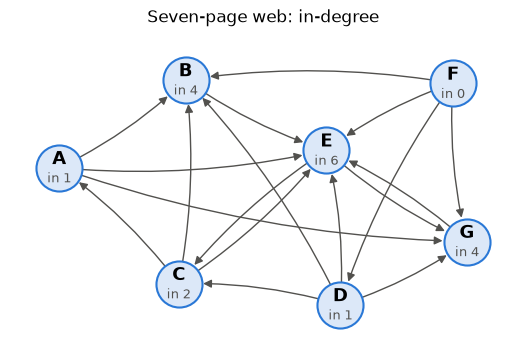

In [2]:
links = PAGERANK_GRAPH
pages = list(links)

in_links = {p: [q for q in pages if p in links[q]] for p in pages}
in_degree = {p: len(in_links[p]) for p in pages}

print_table(
    [[p, ", ".join(links[p]), ", ".join(in_links[p]) or "(none)", in_degree[p]] for p in pages],
    headers=["page", "links to", "linked from", "in-degree"],
)
draw_graph(links, PAGERANK_POS, labels={p: f"in {in_degree[p]}" for p in pages},
           title="Seven-page web: in-degree")
plt.show()

By in-degree, E ranks first, and B and G tie with four incoming links each. But G receives a
link from E, the centre of the graph, while B's links come from A, C, D, and F, which are minor
pages themselves. A recommendation from an important page should count more. In-degree is also
cheap to fake: a link farm of a thousand pages adds a thousand incoming links at almost no cost.

## 2. The Random Surfer

PageRank defines importance by a thought experiment. A random surfer starts on some page and
browses forever. With probability $\alpha$, the surfer clicks one of the links on the page, each
with equal probability. With probability $1 - \alpha$, or always on a page without links, the
surfer jumps to a random page. The PageRank of a page is the long-run fraction of time the
surfer spends there. We can simply let the surfer run:

In [3]:
def random_surfer(links, alpha=0.85, steps=200_000, seed=1):
    """Fraction of steps a random surfer spends on each page."""
    rng = np.random.default_rng(seed)
    pages = list(links)
    visits = Counter()
    page = pages[rng.integers(len(pages))]
    for _ in range(steps):
        visits[page] += 1
        out = links[page]
        if out and rng.random() < alpha:
            page = out[rng.integers(len(out))]          # follow a link
        else:
            page = pages[rng.integers(len(pages))]      # jump to a random page
    return {p: visits[p] / steps for p in pages}

simulated = random_surfer(links)
print_table([[p, f"{simulated[p]:.1%}"] for p in pages], headers=["page", "share of visits"])

| page   | share of visits   |
|:-------|:------------------|
| A      | 7.4%              |
| B      | 10.5%             |
| C      | 18.5%             |
| D      | 2.6%              |
| E      | 37.6%             |
| F      | 2.1%              |
| G      | 21.3%             |

E gets the most visits, and G and C now get more than B. The simulation is noisy and slow:
200,000 steps for seven pages. The book computes the same distribution exactly with power
iteration.

## 3. Power Iteration

Column $j$ of the transition matrix $\mathbf{M}$ describes where the surfer goes from page $p_j$:

$$M_{i,j} = \begin{cases} \frac{1}{L(p_j)} & \text{if } p_j \rightarrow p_i \\ \frac{1}{N} & \text{if } p_j \text{ has no outgoing links} \\ 0 & \text{otherwise} \end{cases}$$

In [4]:
def transition_matrix(links):
    """Column-stochastic matrix M: column j spreads page j's PageRank over its links."""
    pages = list(links)
    idx = {p: i for i, p in enumerate(pages)}
    N = len(pages)
    M = np.zeros((N, N))
    for j, p in enumerate(pages):
        if links[p]:
            for q in links[p]:
                M[idx[q], j] = 1 / len(links[p])
        else:
            M[:, j] = 1 / N
    return M

M = transition_matrix(links)

print_table(
    [[f"to {pages[i]}"] + [str(Fraction(x).limit_denominator(10)) if x else "" for x in M[i]]
     for i in range(len(pages))],
    headers=[""] + [f"from {p}" for p in pages],
)
display_md(f"Every column sums to 1: {np.allclose(M.sum(axis=0), 1)}")

|      | from A   |   from B | from C   | from D   | from E   | from F   |   from G |
|:-----|:---------|---------:|:---------|:---------|:---------|:---------|---------:|
| to A |          |          | 1/3      |          |          |          |          |
| to B | 1/3      |          | 1/3      | 1/4      |          | 1/4      |          |
| to C |          |          |          | 1/4      | 1/2      |          |          |
| to D |          |          |          |          |          | 1/4      |          |
| to E | 1/3      |        1 | 1/3      | 1/4      |          | 1/4      |        1 |
| to F |          |          |          |          |          |          |          |
| to G | 1/3      |          |          | 1/4      | 1/2      | 1/4      |          |

Every column sums to 1: True

Power iteration starts with the uniform distribution and applies the PageRank equation until
the vector changes by less than $\varepsilon$ (L1 norm):

$$\mathbf{r}^{(t+1)} = \frac{1 - \alpha}{N} \cdot \mathbf{1} + \alpha \cdot \mathbf{M} \mathbf{r}^{(t)}$$

The function also accepts a jump distribution $\mathbf{s}$ in place of the uniform
$\frac{1}{N} \cdot \mathbf{1}$, which we need for Personalized PageRank in section 5.

In [5]:
def pagerank(M, alpha=0.85, s=None, eps=1e-8, max_iter=1000):
    """Power iteration; returns the final vector, all iterates, and the L1 change per step."""
    N = M.shape[0]
    s = np.full(N, 1 / N) if s is None else s
    r = np.full(N, 1 / N)
    history, deltas = [r], []
    for _ in range(max_iter):
        r_next = (1 - alpha) * s + alpha * M @ r
        deltas.append(np.abs(r_next - r).sum())
        r = r_next
        history.append(r)
        if deltas[-1] < eps:
            break
    return r, history, deltas

pr, history, deltas = pagerank(M)
E, F = pages.index("E"), pages.index("F")

print_table(
    [[t] + [f"{x:.3f}" for x in history[t]] for t in [0, 1, 2, 3, 5, 10]]
    + [[len(deltas)] + [f"{x:.3f}" for x in pr]],
    headers=["iteration"] + pages,
)
display_md(
    f"After one iteration, PR(E) = {history[1][E]:.3f} and PR(F) = {history[1][F]:.3f}; "
    f"F has no incoming links and keeps only its jump share (1 - α)/N.\n\n"
    f"The change drops below 1e-4 after **{next(t for t, d in enumerate(deltas, 1) if d < 1e-4)}** "
    f"iterations and below 1e-8 after **{len(deltas)}**."
)

|   iteration |     A |     B |     C |     D |     E |     F |     G |
|------------:|------:|------:|------:|------:|------:|------:|------:|
|           0 | 0.143 | 0.143 | 0.143 | 0.143 | 0.143 | 0.143 | 0.143 |
|           1 | 0.062 | 0.163 | 0.112 | 0.052 | 0.406 | 0.021 | 0.183 |
|           2 | 0.053 | 0.086 | 0.205 | 0.026 | 0.381 | 0.021 | 0.227 |
|           3 | 0.08  | 0.105 | 0.189 | 0.026 | 0.371 | 0.021 | 0.208 |
|           5 | 0.074 | 0.105 | 0.186 | 0.026 | 0.376 | 0.021 | 0.212 |
|          10 | 0.074 | 0.105 | 0.186 | 0.026 | 0.375 | 0.021 | 0.212 |
|          36 | 0.074 | 0.105 | 0.186 | 0.026 | 0.375 | 0.021 | 0.212 |

After one iteration, PR(E) = 0.406 and PR(F) = 0.021; F has no incoming links and keeps only its jump share (1 - α)/N.

The change drops below 1e-4 after **15** iterations and below 1e-8 after **36**.

The final values, next to the in-degree:

|               | A    | B     | C     | D    | E     | F    | G     |
|:--------------|:-----|:------|:------|:-----|:------|:-----|:------|
| in-degree     | 1    | 4     | 2     | 1    | 6     | 0    | 4     |
| PageRank      | 7.4% | 10.5% | 18.6% | 2.6% | 37.5% | 2.1% | 21.2% |
| random surfer | 7.4% | 10.5% | 18.5% | 2.6% | 37.6% | 2.1% | 21.3% |

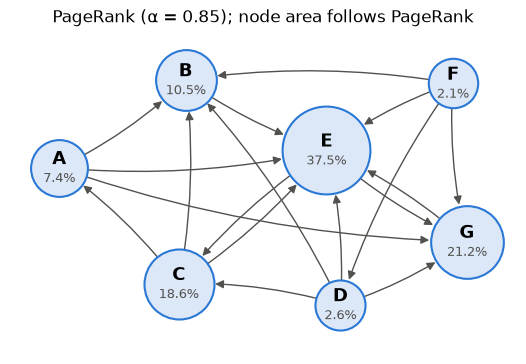

In [6]:
print_table(
    [["in-degree"] + [in_degree[p] for p in pages],
     ["PageRank"] + [f"{x:.1%}" for x in pr],
     ["random surfer"] + [f"{simulated[p]:.1%}" for p in pages]],
    headers=[""] + pages,
)
draw_graph(links, PAGERANK_POS, sizes=dict(zip(pages, pr)),
           labels={p: f"{x:.1%}" for p, x in zip(pages, pr)},
           title="PageRank (α = 0.85); node area follows PageRank")
plt.show()

Power iteration and the simulated surfer agree to within a few tenths of a percent.

### Why G and C overtake B

Each page $q$ passes $\alpha \cdot \text{PR}(q) / L(q)$ along each of its links. Here is what
B and G receive from each of their four incoming links:

In [7]:
def contributions(target, pr, alpha=0.85):
    """What each linking page passes to `target` at the fixed point, plus the jump share."""
    rows, total = [], (1 - alpha) / len(pages)
    for q in in_links[target]:
        share = alpha * pr[pages.index(q)] / len(links[q])
        total += share
        rows.append([q, f"{pr[pages.index(q)]:.1%}", len(links[q]), f"{share:.1%}"])
    rows.append(["random jump", "", "", f"{(1 - alpha) / len(pages):.1%}"])
    rows.append([f"**PR({target})**", "", "", f"**{total:.1%}**"])
    return rows

for target in ["B", "G"]:
    print_table(contributions(target, pr),
                headers=[f"{target} linked from", "PR(q)", "L(q)", "passes on"])

| B linked from   | PR(q)   |   L(q) | passes on   |
|:----------------|:--------|-------:|:------------|
| A               | 7.4%    |      3 | 2.1%        |
| C               | 18.6%   |      3 | 5.3%        |
| D               | 2.6%    |      4 | 0.6%        |
| F               | 2.1%    |      4 | 0.5%        |
| random jump     |         |        | 2.1%        |
| **PR(B)**       |         |        | **10.5%**   |

| G linked from   | PR(q)   |   L(q) | passes on   |
|:----------------|:--------|-------:|:------------|
| A               | 7.4%    |      3 | 2.1%        |
| D               | 2.6%    |      4 | 0.6%        |
| E               | 37.5%   |      2 | 15.9%       |
| F               | 2.1%    |      4 | 0.5%        |
| random jump     |         |        | 2.1%        |
| **PR(G)**       |         |        | **21.2%**   |

The contributions add up to the PageRank of the target. E has only two outgoing links, so C and
G each receive 42.5% of E's PageRank. That single link outweighs all of B's four links, which come from weak pages that split their PageRank across
three or four targets.

## 4. The Damping Factor α

With a small $\alpha$ the random jump dominates and all pages move towards $\frac{1}{N}$. With
$\alpha$ close to 1 the link structure dominates, weak pages lose almost everything, and the
iteration needs more steps:

In [8]:
alphas = [0.50, 0.85, 0.95]
runs = {a: pagerank(M, alpha=a) for a in alphas}

print_table(
    [[f"{a:.2f}"] + [f"{x:.1%}" for x in runs[a][0]] + [len(runs[a][2])] for a in alphas],
    headers=["α"] + pages + ["iterations to 1e-8"],
)

|    α | A    | B     | C     | D    | E     | F    | G     |   iterations to 1e-8 |
|-----:|:-----|:------|:------|:-----|:------|:-----|:------|---------------------:|
| 0.5  | 9.7% | 13.2% | 15.3% | 8.0% | 28.7% | 7.1% | 17.8% |                   17 |
| 0.85 | 7.4% | 10.5% | 18.6% | 2.6% | 37.5% | 2.1% | 21.2% |                   36 |
| 0.95 | 7.0% | 9.6%  | 19.8% | 0.9% | 39.8% | 0.7% | 22.2% |                   47 |

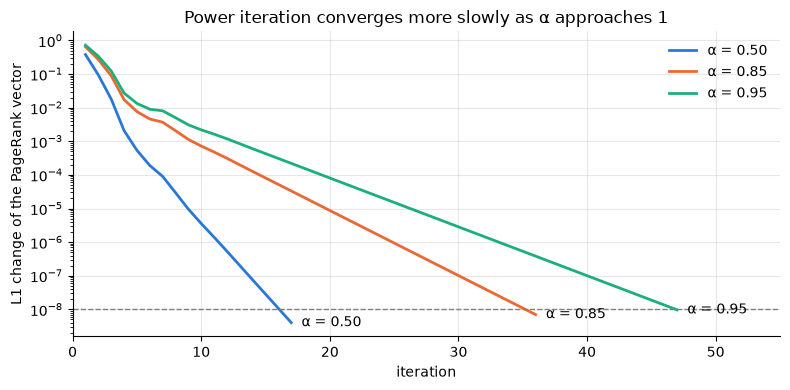

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
for a, color in zip(alphas, ["#2a78d6", "#eb6834", "#1baf7a"]):
    d = runs[a][2]
    ax.semilogy(range(1, len(d) + 1), d, color=color, lw=2, label=f"α = {a:.2f}")
    ax.text(len(d) + 0.8, d[-1], f"α = {a:.2f}", va="center", fontsize=10)
ax.axhline(1e-8, color="gray", lw=1, ls="--")
ax.set_xlim(0, 55)
ax.set_xlabel("iteration")
ax.set_ylabel("L1 change of the PageRank vector")
ax.set_title("Power iteration converges more slowly as α approaches 1")
ax.grid(True, alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

After a few steps, the change shrinks by a constant factor per iteration, so the lines become
straight on the log scale. This factor is at most $\alpha$ (precisely: $\alpha$ times the
second-largest eigenvalue magnitude of $\mathbf{M}$), so the larger $\alpha$, the slower the
convergence.

### The rank sink

Why not $\alpha = 1$? Suppose E drops its link to C. Then E and G link only to each other, and
a surfer who enters the pair never leaves. We run 100 iterations with and without the random
jump:

In [10]:
sink_links = dict(links, E=["G"])
M_sink = transition_matrix(sink_links)

rows = []
for a in [1.0, 0.85]:
    r, _, _ = pagerank(M_sink, alpha=a, max_iter=100, eps=0)
    rows.append([f"{a:.2f}"] + [f"{x:.1%}" for x in r] + [f"{r[E] + r[pages.index('G')]:.1%}"])
print_table(rows, headers=["α"] + pages + ["E + G"])

|    α | A    | B    | C    | D    | E     | F    | G     | E + G   |
|-----:|:-----|:-----|:-----|:-----|:------|:-----|:------|:--------|
| 1    | 0.0% | 0.0% | 0.0% | 0.0% | 47.7% | 0.0% | 52.3% | 100.0%  |
| 0.85 | 2.9% | 4.7% | 2.7% | 2.6% | 43.8% | 2.1% | 41.2% | 84.9%   |

Without the jump, E and G absorb all PageRank and every other page drops to 0. The jump
guarantees that the surfer can always leave, which makes the stationary distribution unique.

## 5. Personalized PageRank

If the surfer always jumps back to a fixed set of pages $\mathbb{S}$, PageRank measures
importance *from the point of view of* $\mathbb{S}$:

$$\mathbf{r} = (1 - \alpha) \cdot \mathbf{s} + \alpha \cdot \mathbf{M} \mathbf{r}$$

We let the surfer always jump back to a single page, as if it were the user's own page, once
for A and once for D:

In [11]:
def personalized(seed_pages, alpha=0.85):
    """PageRank with the random jump restricted to `seed_pages`."""
    s = np.array([1.0 if p in seed_pages else 0.0 for p in pages])
    return pagerank(M, alpha=alpha, s=s / s.sum())[0]

print_table(
    [["PageRank"] + [f"{x:.1%}" for x in pr]]
    + [[f"Personalized, S = {{{seed}}}"] + [f"{x:.1%}" for x in personalized({seed})]
       for seed in ["A", "D"]],
    headers=[""] + pages,
)

|                       | A     | B     | C     | D     | E     | F    | G     |
|:----------------------|:------|:------|:------|:------|:------|:-----|:------|
| PageRank              | 7.4%  | 10.5% | 18.6% | 2.6%  | 37.5% | 2.1% | 21.2% |
| Personalized, S = {A} | 19.3% | 9.7%  | 15.1% | 0.0%  | 35.4% | 0.0% | 20.5% |
| Personalized, S = {D} | 5.0%  | 9.6%  | 17.6% | 15.0% | 33.9% | 0.0% | 19.0% |

With $\mathbb{S} = \{A\}$, A climbs from fifth to third place, and the pages that A links to
gain. D and F drop to 0: no path of links leads from A to them, so the surfer never gets there.
With $\mathbb{S} = \{D\}$, D itself jumps from 2.6% to 15%. E stays first in every case, since
in this small graph almost every path leads to E. With $\mathbb{S}$ chosen as one user in a
social network, the same computation ranks "people you may know".

## 6. Hubs and Authorities: HITS

HITS assigns two values to each page of a query-specific base set: an **authority** value (a
good source, linked from good hubs) and a **hub** value (a good list, linking to good
authorities). The book's eight-page base set:

| A[i,j]   | A   |   B |   C |   D |   E |   F |   G | H   |
|:---------|:----|----:|----:|----:|----:|----:|----:|:----|
| A        |     |   1 |   1 |   1 |   1 |     |   1 |     |
| B        |     |     |     |   1 |     |     |   1 |     |
| C        |     |     |     |     |     |     |     |     |
| D        |     |     |   1 |     |     |     |     |     |
| E        |     |     |     |   1 |     |     |     |     |
| F        |     |     |     |   1 |   1 |     |   1 |     |
| G        |     |     |   1 |   1 |     |     |     |     |
| H        |     |     |     |   1 |     |   1 |   1 |     |

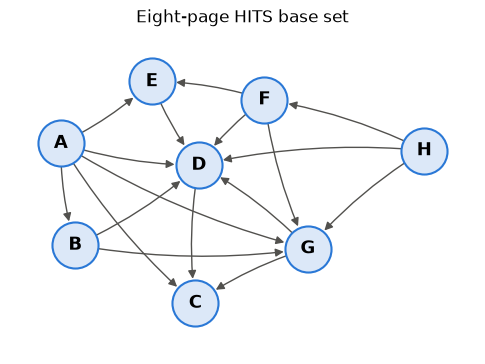

In [12]:
h_pages = list(HITS_GRAPH)
A = np.array([[1 if q in HITS_GRAPH[p] else 0 for q in h_pages] for p in h_pages])

print_table([[p] + [x or "" for x in row] for p, row in zip(h_pages, A)],
            headers=["A[i,j]"] + h_pages)
draw_graph(HITS_GRAPH, HITS_POS, title="Eight-page HITS base set")
plt.show()

The update sums hub values into authorities and authority values into hubs, then normalizes
both vectors to unit length:

$$a^{(t+1)}(p) = \sum_{q \rightarrow p} h^{(t)}(q) \qquad h^{(t+1)}(p) = \sum_{p \rightarrow q} a^{(t)}(q)$$

In matrix form, $\mathbf{a}^{(t+1)} = \mathbf{A}^{\top} \mathbf{h}^{(t)}$ and
$\mathbf{h}^{(t+1)} = \mathbf{A} \mathbf{a}^{(t)}$.

In [13]:
def hits(A, eps=1e-8, max_iter=1000):
    """HITS power iteration from a = h = sqrt(1/N); returns authorities, hubs, iterations."""
    N = A.shape[0]
    a = h = np.full(N, np.sqrt(1 / N))
    for t in range(1, max_iter + 1):
        a_next, h_next = A.T @ h, A @ a
        a_next, h_next = a_next / np.linalg.norm(a_next), h_next / np.linalg.norm(h_next)
        delta = np.abs(a_next - a).sum() + np.abs(h_next - h).sum()
        a, h = a_next, h_next
        if delta < eps:
            break
    return a, h, t

auth, hub, n_iter = hits(A)
print_table(
    [[p, hub[i], auth[i]] for i, p in enumerate(h_pages)],
    headers=["page", "hub h", "authority a"], floatfmt=".2f",
)
display_md(f"Converged after {n_iter} iterations.")

| page   |   hub h |   authority a |
|:-------|--------:|--------------:|
| A      |    0.60 |          0.00 |
| B      |    0.37 |          0.18 |
| C      |    0.00 |          0.29 |
| D      |    0.09 |          0.69 |
| E      |    0.21 |          0.31 |
| F      |    0.46 |          0.12 |
| G      |    0.29 |          0.54 |
| H      |    0.40 |          0.00 |

Converged after 26 iterations.

The values match the book: A is the best hub, D the best authority, followed by G. C has no
outgoing links and H no incoming links, so they are pure types. As in PageRank, this is a power
iteration: $\mathbf{a}$ converges to the principal eigenvector of $\mathbf{A}^{\top}\mathbf{A}$,
and $\mathbf{h}$ to that of $\mathbf{A}\mathbf{A}^{\top}$. We can check this directly:

In [14]:
def principal_eigenvector(S):
    values, vectors = np.linalg.eigh(S)        # symmetric matrix, eigenvalues ascending
    v = vectors[:, -1]
    return v * np.sign(v.sum())                # choose the non-negative orientation

display_md(
    f"Authorities equal the principal eigenvector of AᵀA: "
    f"**{np.allclose(auth, principal_eigenvector(A.T @ A), atol=1e-6)}**  \n"
    f"Hubs equal the principal eigenvector of AAᵀ: "
    f"**{np.allclose(hub, principal_eigenvector(A @ A.T), atol=1e-6)}**"
)

Authorities equal the principal eigenvector of AᵀA: **True**  
Hubs equal the principal eigenvector of AAᵀ: **True**

### Why E beats C

E has two incoming links and C has three, yet E is the better authority. Before normalization,
an authority value is the sum of the hub values of the linking pages:

In [15]:
rows = []
for target in ["E", "C"]:
    sources = [q for q in h_pages if target in HITS_GRAPH[q]]
    total = sum(hub[h_pages.index(q)] for q in sources)
    rows.append([target, ", ".join(f"{q} ({hub[h_pages.index(q)]:.2f})" for q in sources),
                 f"{total:.2f}"])
print_table(rows, headers=["authority", "linked from (hub value)", "sum"])

| authority   | linked from (hub value)      |   sum |
|:------------|:-----------------------------|------:|
| E           | A (0.60), F (0.46)           |  1.06 |
| C           | A (0.60), D (0.09), G (0.29) |  0.98 |

E is linked by the two strong hubs A and F. C is linked by A, by the average hub G, and by the
weak hub D. Mutual reinforcement rewards *who* links, not how many.

### Optional: SALSA

SALSA (Lempel and Moran) replaces the sums with a random walk: each hub splits its value over its
outgoing links, and each authority splits its value over its incoming links.

$$a^{(t+1)}(p) = \sum_{q \rightarrow p} \frac{h^{(t)}(q)}{\text{out}(q)} \qquad h^{(t+1)}(q) = \sum_{q \rightarrow p} \frac{a^{(t)}(p)}{\text{in}(p)}$$

In [16]:
def salsa(A, n_iter=200):
    """SALSA random walk; both vectors stay probability distributions."""
    out_deg, in_deg = A.sum(axis=1), A.sum(axis=0)
    h = (out_deg > 0) / (out_deg > 0).sum()
    a = (in_deg > 0) / (in_deg > 0).sum()
    for _ in range(n_iter):
        a_next = A.T @ np.divide(h, out_deg, out=np.zeros_like(h), where=out_deg > 0)
        h_next = A @ np.divide(a, in_deg, out=np.zeros_like(a), where=in_deg > 0)
        a, h = a_next, h_next
    return a, h

s_auth, s_hub = salsa(A)
n_links = A.sum()
print_table(
    [[p, auth[i], f"{s_auth[i]:.1%}", f"{A[:, i].sum()}/{n_links}",
      f"{s_hub[i]:.1%}", f"{A[i].sum()}/{n_links}"] for i, p in enumerate(h_pages)],
    headers=["page", "HITS a", "SALSA a", "in-degree / links", "SALSA h", "out-degree / links"],
    floatfmt=("", ".2f"),
)

| page   |   HITS a | SALSA a   | in-degree / links   | SALSA h   | out-degree / links   |
|:-------|---------:|:----------|:--------------------|:----------|:---------------------|
| A      |     0.00 | 0.0%      | 0/17                | 29.4%     | 5/17                 |
| B      |     0.18 | 5.9%      | 1/17                | 11.8%     | 2/17                 |
| C      |     0.29 | 17.6%     | 3/17                | 0.0%      | 0/17                 |
| D      |     0.69 | 35.3%     | 6/17                | 5.9%      | 1/17                 |
| E      |     0.31 | 11.8%     | 2/17                | 5.9%      | 1/17                 |
| F      |     0.12 | 5.9%      | 1/17                | 17.6%     | 3/17                 |
| G      |     0.54 | 23.5%     | 4/17                | 11.8%     | 2/17                 |
| H      |     0.00 | 0.0%      | 0/17                | 17.6%     | 3/17                 |

The walk converges to the closed form of Lempel and Moran: in a connected base set, the
authority value is the in-degree divided by the number of links, and the hub value the
out-degree divided by the number of links. SALSA therefore ranks C (three links) above E (two
links), the reverse of HITS: it ignores how strong the linking hubs are.

## Payoff: the Question of Section 1

In section 1, in-degree tied B and G and could not see that G is linked by the most important
page. PageRank answers the question:

In [17]:
rank_in = sorted(pages, key=lambda p: -in_degree[p])
rank_pr = sorted(pages, key=lambda p: -pr[pages.index(p)])

print_table(
    [[k + 1, f"{rank_in[k]} ({in_degree[rank_in[k]]})", f"{rank_pr[k]} ({pr[pages.index(rank_pr[k])]:.1%})"]
     for k in range(len(pages))],
    headers=["rank", "by in-degree (links)", "by PageRank"],
)

|   rank | by in-degree (links)   | by PageRank   |
|-------:|:-----------------------|:--------------|
|      1 | E (6)                  | E (37.5%)     |
|      2 | B (4)                  | G (21.2%)     |
|      3 | G (4)                  | C (18.6%)     |
|      4 | C (2)                  | B (10.5%)     |
|      5 | A (1)                  | A (7.4%)      |
|      6 | D (1)                  | D (2.6%)      |
|      7 | F (0)                  | F (2.1%)      |

<div style="border-left: 4px solid #C8102E; background: rgba(200, 16, 46, 0.06); padding: 0.6em 0.9em; margin: 0.6em 0; border-radius: 4px;">
<strong style="color:#C8102E; text-transform:uppercase; font-size:0.78em; letter-spacing:0.06em;">A link is worth as much as the page it comes from</strong><br>
PageRank lets every page pass its own importance, split over its outgoing links. G and C overtake B because the strongest page, E, links to them with only two links. HITS applies the same idea to a query-specific base set with two roles: good hubs make good authorities. Both are power iterations that converge to an eigenvector of a link matrix.
</div>

## Summary

In-degree counts links; PageRank weighs them by the importance of the linking page and divides
by its number of outgoing links. Power iteration on the transition matrix computes the
stationary distribution of the random surfer in a few dozen iterations, and the random jump
with probability $1 - \alpha$ prevents rank sinks. A jump set turns PageRank into Personalized
PageRank. HITS computes hub and authority values on a small base set at query time; SALSA
replaces its sums by a random walk and reduces to in-degree counts. How a search engine combines
PageRank with the content signals of ch08-01 is the topic of learning to rank (ch08-03).

## Try it yourself

1. **Dangling node.** Remove G's only link (`dict(links, G=[])`) and recompute PageRank. Column
   G of $\mathbf{M}$ becomes $\frac{1}{N}$ everywhere. Which page loses most?
2. **Link farm.** Add $k$ new pages that all link to D and nothing else. How large must $k$ be
   before D overtakes G? Why would this not work on a web of billions of pages?
3. **Tightly knit community.** Add three new pages to the HITS base set that all link to each
   other and to C. Compare HITS and SALSA authorities. Which method is more robust?